# Data Cleaning, Preprocessing & Feature Engineering
## Motor anomaly-detection project

**Owner:** Task 2  
**Input:** `Final_labeled.csv`  
**Goal:** create a reproducible feature matrix for Robust Statistical Baseline, Isolation Forest, LOF, and optionally One-Class SVM.

### Important design choices
- `label` is kept separate from the model features. It must never be passed into model `.fit()` as an input feature.
- `File` and `Date` are metadata, not sensor measurements; they are excluded from the numeric feature matrix.
- Anomalies are **not deleted** just because they are extreme: those are the observations the project is trying to detect.
- Missing `File`/`Date` values are reported but do not trigger row deletion.
- Scaling is fitted on training data only in the final experiment to avoid leakage.
- `temp_rise = temp_mot - temp_amb` is included as a candidate engineered feature. Compare results with/without it before deciding to keep it.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

In [2]:
df = pd.read_csv("Final_labeled.csv")

print("Shape:", df.shape)
display(df.head())

Shape: (3377, 52)


,File,Date,speed_rpm,speed_Hz,Current,Voltage,temp_mot,temp_amb,1x[Vibration],2x[Vibration],...,0-4k_Hz[Current],4k-8k_Hz[Current],8k-16kHz[Current],16k-26kHz[Current],0-4k_Hz[Voltage],4k-8k_Hz[Voltage],8k-16kHz[Voltage],16k-26kHz[Voltage],label,data_type
0,MOTOR-DC_2020_12_02_17_25_04_Analogico.hdf5,"02/12/2020 17:25:03,604",7919.375470,131.989591,1.609338,2.968187,26.093293,21.739496,0.130761,0.063540,...,4.087496,3.148589,5.021231,5.082819,1.878607,1.839876,3.634174,4.343698,normal,real
1,MOTOR-DC_2020_12_02_17_25_08_Analogico.hdf5,"02/12/2020 17:25:07,815",7968.161802,132.802697,1.784386,2.951127,26.035966,21.755127,0.129288,0.065533,...,3.837930,2.972374,4.929544,5.110133,1.850483,1.820347,3.600817,4.306598,normal,real
2,MOTOR-DC_2020_12_02_17_25_12_Analogico.hdf5,"02/12/2020 17:25:12,211",7979.458729,132.990979,1.606156,2.966607,25.968306,21.738585,0.076860,0.069520,...,3.838140,2.927193,4.869216,5.119583,1.945781,1.923535,3.799816,4.528593,normal,real
3,MOTOR-DC_2020_12_02_17_25_17_Analogico.hdf5,"02/12/2020 17:25:16,610",7964.340995,132.739017,1.793934,2.954286,25.977693,21.763899,0.070569,0.054715,...,4.422911,3.360474,5.554649,5.951284,1.946259,1.907213,3.773093,4.499607,normal,real
4,MOTOR-DC_2020_12_02_17_25_21_Analogico.hdf5,"02/12/2020 17:25:21,015",7979.410686,132.990178,1.720732,2.953338,26.005912,21.763027,0.122334,0.085772,...,4.542497,3.367668,5.913092,6.559495,2.024858,1.986529,3.925885,4.736751,normal,real


## 1. Initial audit

In [3]:
print("Rows, columns:", df.shape)
print("\nColumn types:")
display(df.dtypes.value_counts().rename_axis("dtype").to_frame("count"))

print("\nExact duplicate rows:", int(df.duplicated().sum()))
print("\nLabels:")
display(df["label"].value_counts(dropna=False).to_frame("count"))
display((df["label"].value_counts(normalize=True, dropna=False) * 100).round(2).rename("percent").to_frame())

print("\nSource type by label:")
display(pd.crosstab(df["data_type"], df["label"], margins=True))

missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

Rows, columns: (3377, 52)

Column types:


,count
dtype,
float64,48
object,4



Exact duplicate rows: 0

Labels:


,count
label,
normal,3310
anomaly,67


,percent
label,
normal,98.02
anomaly,1.98



Source type by label:


label,anomaly,normal,All
data_type,,,
real,8,369,377
synthetic,59,2941,3000
All,67,3310,3377


,missing_count
File,3000
Date,3000


## 2. Missing values and duplicates

The initial dataset contains 3,377 rows and 52 columns. The `File` and `Date` fields are missing in the synthetic records; these are metadata fields and are excluded from model features. Do not drop those rows for this reason alone.

We remove only exact duplicate rows. We do **not** delete high/low sensor values automatically, because outliers may represent the anomalies of interest.

In [4]:
df = df.drop_duplicates().copy()

metadata_cols = [c for c in ["File", "Date", "label", "data_type"] if c in df.columns]
feature_cols = [c for c in df.columns if c not in metadata_cols]

# Convert expected sensor features to numeric; invalid strings become NaN and are audited below.
df[feature_cols] = df[feature_cols].apply(pd.to_numeric, errors="coerce")
df[feature_cols] = df[feature_cols].replace([np.inf, -np.inf], np.nan)

feature_missing = df[feature_cols].isna().sum().sort_values(ascending=False)
print("Missing values in sensor features:")
display(feature_missing[feature_missing > 0].to_frame("missing_count"))

print("Missing values in metadata (reported, not imputed):")
display(df[[c for c in ["File", "Date"] if c in df.columns]].isna().sum().to_frame("missing_count"))

Missing values in sensor features:


,missing_count


Missing values in metadata (reported, not imputed):


,missing_count
File,3000
Date,3000


## 3. Data quality checks and distributions

In [5]:
numeric_summary = df[feature_cols].describe().T
numeric_summary["missing_count"] = df[feature_cols].isna().sum()
numeric_summary["unique_count"] = df[feature_cols].nunique(dropna=True)
display(numeric_summary)

# Check for constant features
constant_features = [c for c in feature_cols if df[c].nunique(dropna=True) <= 1]
print("Constant features:", constant_features)

# Check speed relationship; RPM should be approximately 60 * Hz if both columns use the expected units.
if {"speed_rpm", "speed_Hz"}.issubset(df.columns):
    speed_error = (df["speed_rpm"] - 60 * df["speed_Hz"]).abs()
    print("Median |RPM - 60*Hz|:", speed_error.median())
    print("Correlation speed_rpm vs 60*speed_Hz:", df["speed_rpm"].corr(60 * df["speed_Hz"]))

,count,mean,std,min,25%,50%,75%,max,missing_count,unique_count
speed_rpm,3377.0,8808.067709,1004.977168,6013.559263,7894.724718,8163.772347,9764.574277,13041.030144,0,3374
speed_Hz,3377.0,146.801128,16.749619,100.225988,131.578745,136.062872,162.742905,217.350502,0,3374
Current,3377.0,2.041980,0.587142,-0.185699,1.587059,1.840268,2.595650,3.322873,0,3275
Voltage,3377.0,3.850257,0.986801,0.000000,2.960233,3.228453,4.848316,5.758703,0,3280
temp_mot,3377.0,44.805621,12.576795,21.996031,35.433005,39.439394,56.716454,73.081155,0,3377
temp_amb,3377.0,21.973619,0.188076,21.616340,21.825291,21.956037,22.132588,22.360410,0,3377
1x[Vibration],3377.0,2.999963,4.284418,-1.829518,0.153147,1.216190,4.415794,26.151829,0,3377
2x[Vibration],3377.0,2.709445,4.508640,-2.372653,0.066097,0.705814,4.276577,23.954542,0,3377
3x[Vibration],3377.0,2.687173,3.378790,-1.772581,0.121907,0.948875,4.542198,18.451224,0,3377
4x[Vibration],3377.0,2.725804,3.783231,-1.852479,0.062380,0.973271,4.133931,18.456769,0,3377


Constant features: []
Median |RPM - 60*Hz|: 0.0
Correlation speed_rpm vs 60*speed_Hz: 0.9999999999999998


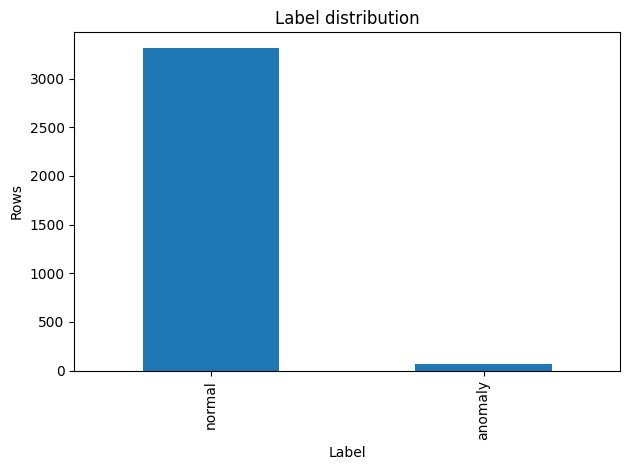

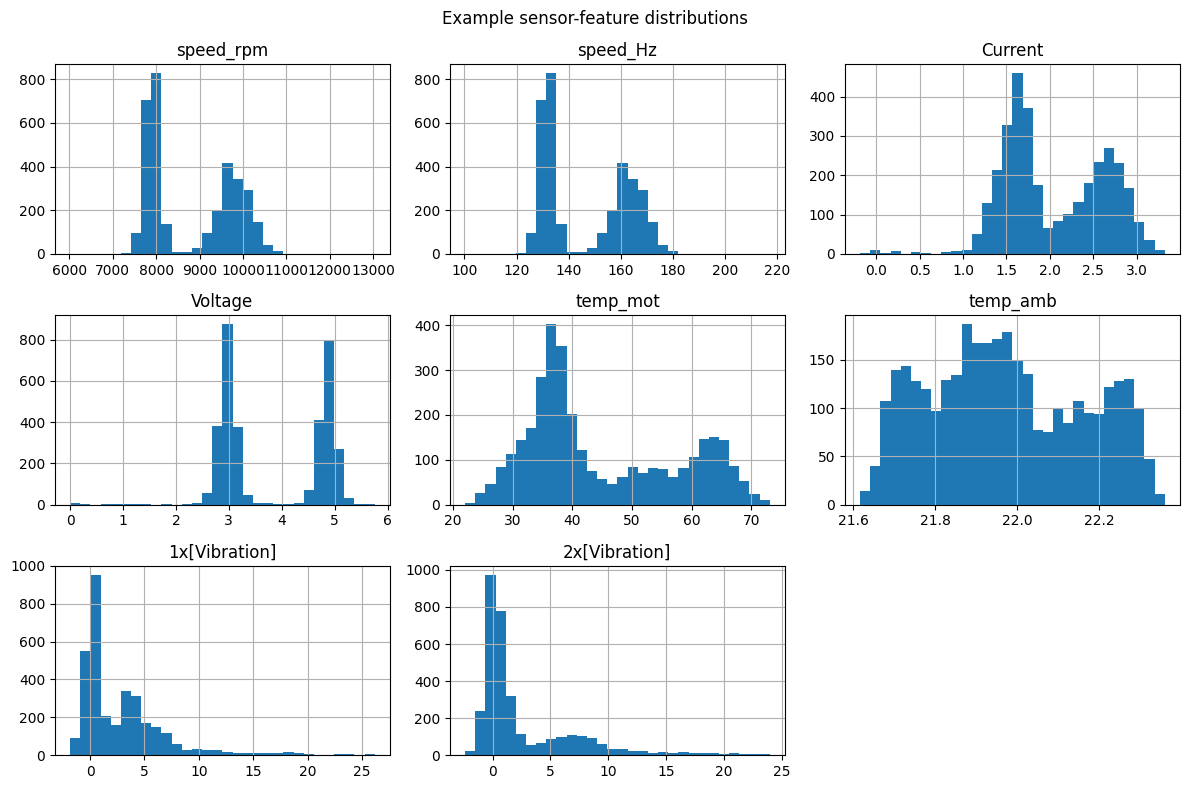

In [6]:
# Label balance
ax = df["label"].value_counts().plot(kind="bar")
ax.set_title("Label distribution")
ax.set_xlabel("Label")
ax.set_ylabel("Rows")
plt.tight_layout()
plt.show()

# Sensor-feature distributions (first 8 features for a compact overview)
df[feature_cols[:8]].hist(figsize=(12, 8), bins=30)
plt.suptitle("Example sensor-feature distributions")
plt.tight_layout()
plt.show()

## 4. Feature engineering

Add only features that have a clear physical interpretation. Here we create `temp_rise`, the motor temperature minus ambient temperature. This may be more informative than motor temperature alone when ambient conditions vary.

We avoid creating arbitrary ratios or dropping correlated features automatically. In particular, inspect `speed_rpm` and `speed_Hz`: if they are nearly deterministic conversions, retaining both may give speed extra weight in distance-based methods such as LOF.

In [7]:
if {"temp_mot", "temp_amb"}.issubset(df.columns):
    df["temp_rise"] = df["temp_mot"] - df["temp_amb"]

engineered_feature_cols = [c for c in df.columns if c not in metadata_cols]
display(df[engineered_feature_cols].describe().T.tail(10))

,count,mean,std,min,25%,50%,75%,max
16k-26kHz[Vibration],3377.0,106.768600,102.390359,-16.917967,28.462983,57.359536,218.303231,368.436206
0-4k_Hz[Current],3377.0,8.159390,4.385437,0.140386,4.975042,7.724119,9.812107,38.176629
4k-8k_Hz[Current],3377.0,5.608337,2.264260,0.025383,3.713025,5.506608,6.894950,16.029224
8k-16kHz[Current],3377.0,9.108571,3.423467,0.118659,6.303260,9.108547,10.912354,26.115319
16k-26kHz[Current],3377.0,9.946203,3.825286,0.174746,6.903239,9.917950,11.793547,29.500878
0-4k_Hz[Voltage],3377.0,2.760202,0.793695,0.478500,2.105307,2.739433,3.165952,7.056036
4k-8k_Hz[Voltage],3377.0,2.638575,0.722492,0.033823,2.052221,2.620117,3.020345,6.167825
8k-16kHz[Voltage],3377.0,5.219202,1.420031,0.043356,4.076641,5.167314,5.969387,12.408156
16k-26kHz[Voltage],3377.0,6.238611,1.693916,0.043605,4.872069,6.178741,7.130933,14.818335
temp_rise,3377.0,22.832002,12.443888,0.275221,13.565597,17.441829,34.660934,50.997000


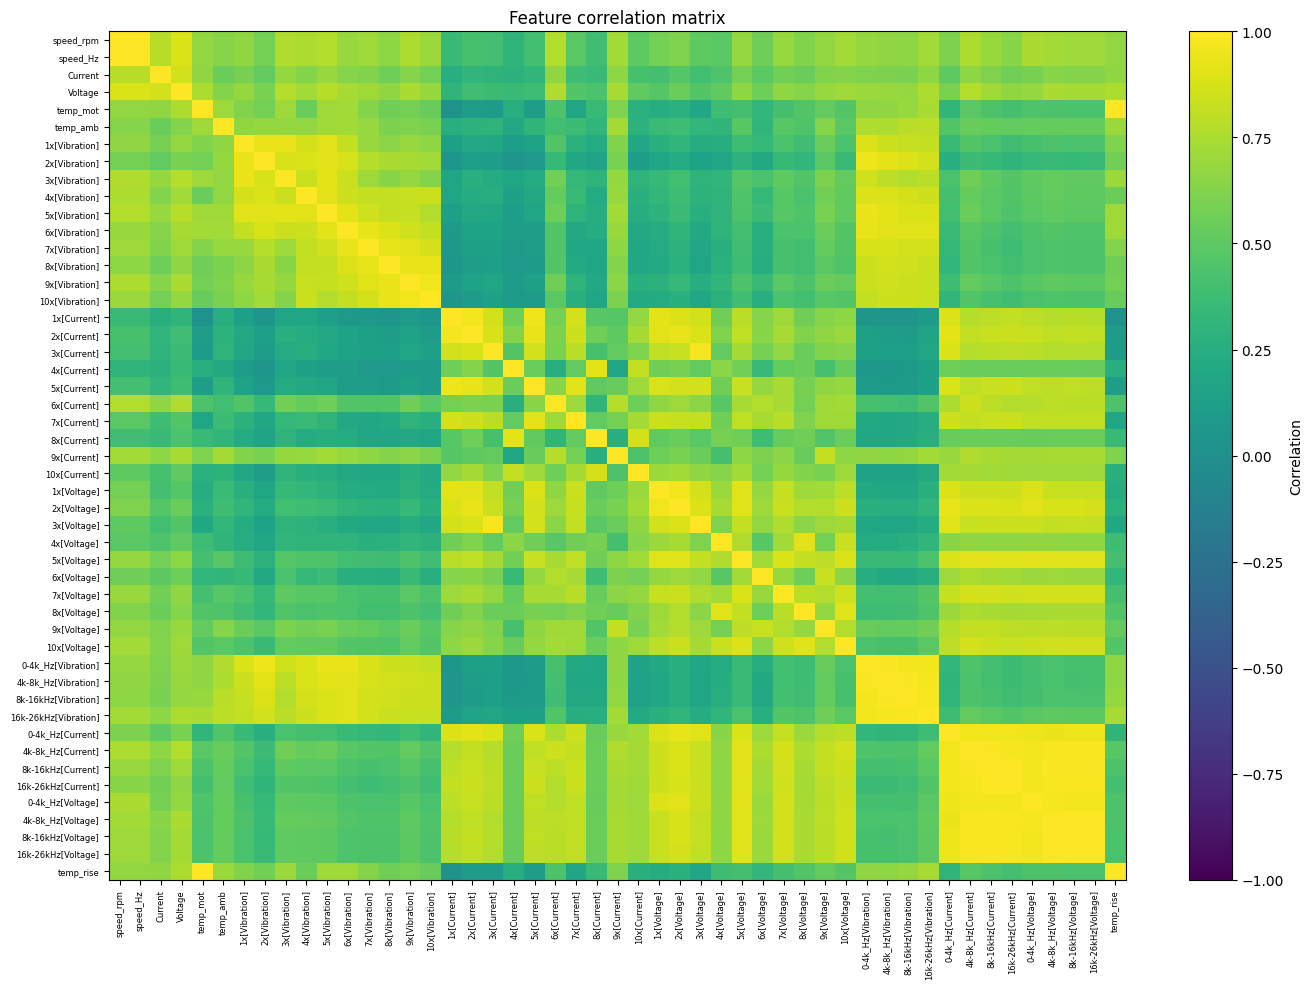

,feature_1,feature_2,absolute_correlation
0,speed_rpm,speed_Hz,1.000000
1,temp_mot,temp_rise,0.999943
2,8k-16kHz[Voltage],16k-26kHz[Voltage],0.999333
3,4k-8k_Hz[Voltage],8k-16kHz[Voltage],0.998763
4,4k-8k_Hz[Voltage],16k-26kHz[Voltage],0.998674
5,8k-16kHz[Current],16k-26kHz[Current],0.996588
6,8k-16kHz[Current],8k-16kHz[Voltage],0.988399
7,4k-8k_Hz[Current],8k-16kHz[Current],0.988073
8,8k-16kHz[Current],16k-26kHz[Voltage],0.988053
9,8k-16kHz[Current],4k-8k_Hz[Voltage],0.987853


In [8]:
# Correlation review: use this to inform a decision, not as an automatic feature-deletion rule.
corr = df[engineered_feature_cols].corr(numeric_only=True)
plt.figure(figsize=(14, 10))
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=6)
plt.yticks(range(len(corr.index)), corr.index, fontsize=6)
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

# Show highly correlated pairs for review
corr_abs = corr.abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
pairs = (
    upper.stack()
    .sort_values(ascending=False)
    .rename("absolute_correlation")
    .reset_index()
)
pairs.columns = ["feature_1", "feature_2", "absolute_correlation"]
display(pairs.head(20))

### Feature and Metadata Separation

Separated sensor features (X), target labels (y), and metadata. Removed features with entirely missing values and checked dataset shapes and label distribution.

In [9]:
metadata_cols = [c for c in ["File", "Date", "label", "data_type"] if c in df.columns]
model_feature_cols = [c for c in df.columns if c not in metadata_cols]

X = df[model_feature_cols].copy()
y = df["label"].copy()
metadata = df[[c for c in ["File", "Date", "data_type"] if c in df.columns]].copy()

# Remove any feature that is entirely missing; this cannot be meaningfully imputed.
all_missing = X.columns[X.isna().all()].tolist()
if all_missing:
    print("Dropping all-missing features:", all_missing)
    X = X.drop(columns=all_missing)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Metadata shape:", metadata.shape)
print("Label distribution:")
display(y.value_counts())

X shape: (3377, 49)
y shape: (3377,)
Metadata shape: (3377, 3)
Label distribution:


,count
label,
normal,3310
anomaly,67


### Chronological Train-Test Split

Splits data chronologically (80% training, 20% testing) when valid dates are available, otherwise uses a stratified random split.

In [10]:
# Use a chronological split when Date represents
# the actual temporal order of the observations.

if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    if df["Date"].notna().all():
        sorted_indices = df.sort_values("Date").index

        split_point = int(len(sorted_indices) * 0.8)

        train_indices = sorted_indices[:split_point]
        test_indices = sorted_indices[split_point:]

        X_train = X.loc[train_indices]
        X_test = X.loc[test_indices]

        y_train = y.loc[train_indices] if y is not None else None
        y_test = y.loc[test_indices] if y is not None else None

    else:
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.2,
            random_state=42,
            stratify=y if y is not None else None
        )

else:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y if y is not None else None
    )

print("Train:", X_train.shape, "Test:", X_test.shape)

print("\nTrain labels:")
display(y_train.value_counts())

print("\nTest labels:")
display(y_test.value_counts())

Train: (2701, 49) Test: (676, 49)

Train labels:


/tmp/ipykernel_573/1124399592.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


,count
label,
normal,2647
anomaly,54



Test labels:


,count
label,
normal,663
anomaly,13


##Model-Specific Preprocessing Pipelines

Created separate preprocessing pipelines for each model, using median imputation for missing values and RobustScaler for LOF and One-Class SVM.

In [11]:
# Robust Statistical Baseline Pipeline

baseline_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Isolation Forest Preprocessing Pipeline

isolation_forest_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# LOF Preprocessing Pipeline

lof_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# One-Class SVM Preprocessing Pipeline

ocsvm_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Fit on training data, transform everything else


In [12]:
# Fit Preprocessing on Training Data Only

X_train_baseline = baseline_preprocessing.fit_transform(X_train)
X_test_baseline = baseline_preprocessing.transform(X_test)

X_train_if = isolation_forest_preprocessing.fit_transform(X_train)
X_test_if = isolation_forest_preprocessing.transform(X_test)

X_train_lof = lof_preprocessing.fit_transform(X_train)
X_test_lof = lof_preprocessing.transform(X_test)

X_train_ocsvm = ocsvm_preprocessing.fit_transform(X_train)
X_test_ocsvm = ocsvm_preprocessing.transform(X_test)

# Summary

print("Preprocessing completed successfully!")

print(f"Number of features: {len(feature_cols)}")
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

print("\nPrepared datasets:")

print("Baseline:", X_train_baseline.shape, X_test_baseline.shape)
print("Isolation Forest:", X_train_if.shape, X_test_if.shape)
print("LOF:", X_train_lof.shape, X_test_lof.shape)
print("One-Class SVM:", X_train_ocsvm.shape, X_test_ocsvm.shape)

Preprocessing completed successfully!
Number of features: 48
Training samples: 2701
Testing samples: 676

Prepared datasets:
Baseline: (2701, 49) (676, 49)
Isolation Forest: (2701, 49) (676, 49)
LOF: (2701, 49) (676, 49)
One-Class SVM: (2701, 49) (676, 49)


### Sanity Check


In [13]:
processed_sets = {
    "Baseline": (X_train_baseline, X_test_baseline),
    "Isolation Forest": (X_train_if, X_test_if),
    "LOF": (X_train_lof, X_test_lof),
    "One-Class SVM": (X_train_ocsvm, X_test_ocsvm),
}

for model_name, (Xtr, Xte) in processed_sets.items():
    Xtr = np.asarray(Xtr, dtype=float)
    Xte = np.asarray(Xte, dtype=float)

    print(f"\n=== {model_name} ===")
    print("Train shape:", Xtr.shape)
    print("Test shape:", Xte.shape)
    print("Train NaNs:", np.isnan(Xtr).sum())
    print("Test NaNs:", np.isnan(Xte).sum())
    print("Train Infs:", np.isinf(Xtr).sum())
    print("Test Infs:", np.isinf(Xte).sum())

    assert Xtr.shape[1] > 0, "No features!"
    assert Xtr.shape[1] == Xte.shape[1], "Feature count mismatch!"
    assert np.isfinite(Xtr).all(), "Invalid values in train!"
    assert np.isfinite(Xte).all(), "Invalid values in test!"

print("\nAll processed datasets passed the checks!")



=== Baseline ===
Train shape: (2701, 49)
Test shape: (676, 49)
Train NaNs: 0
Test NaNs: 0
Train Infs: 0
Test Infs: 0

=== Isolation Forest ===
Train shape: (2701, 49)
Test shape: (676, 49)
Train NaNs: 0
Test NaNs: 0
Train Infs: 0
Test Infs: 0

=== LOF ===
Train shape: (2701, 49)
Test shape: (676, 49)
Train NaNs: 0
Test NaNs: 0
Train Infs: 0
Test Infs: 0

=== One-Class SVM ===
Train shape: (2701, 49)
Test shape: (676, 49)
Train NaNs: 0
Test NaNs: 0
Train Infs: 0
Test Infs: 0

All processed datasets passed the checks!


### Save the fitted pipeline
Saved the fitted preprocessing pipelines using Joblib for future reuse, preserving the learned imputation and scaling parameters.

In [14]:
import joblib
from pathlib import Path

# Create folder
Path("models").mkdir(parents=True, exist_ok=True)

# Save fitted preprocessing pipelines
pipelines = {
    "baseline": baseline_preprocessing,
    "isolation_forest": isolation_forest_preprocessing,
    "lof": lof_preprocessing,
    "one_class_svm": ocsvm_preprocessing
}

for name, pipeline in pipelines.items():
    path = f"models/{name}_preprocessing.pkl"
    joblib.dump(pipeline, path)
    print(f"Saved successfully: {path}")


print("Fitted preprocessing pipeline saved successfully!")

# How the ML teammate can use it (example, not executed):
#   from sklearn.ensemble import IsolationForest
#   model = Pipeline([("prep", loaded), ("model", IsolationForest(random_state=42))])
#   model.fit(X_train_raw)
#   scores = model.decision_function(X_test_raw)

Saved successfully: models/baseline_preprocessing.pkl
Saved successfully: models/isolation_forest_preprocessing.pkl
Saved successfully: models/lof_preprocessing.pkl
Saved successfully: models/one_class_svm_preprocessing.pkl
Fitted preprocessing pipeline saved successfully!


## 8. Save deliverables

The raw engineered features and labels/metadata are saved separately. The scaled train/test files are optional experiment artifacts from the illustrative stratified split. If the ML teammate chooses a different split or trains only on normal data, regenerate those scaled files using that agreed split instead.

In [15]:
output_dir = Path("deliverables")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Save raw engineered features
X.to_csv(output_dir / "raw_engineered_features.csv", index=True)

# 2. Save labels separately
y.to_frame(name="label").to_csv(
    output_dir / "labels.csv",
    index=True
)

# 3. Save metadata separately
metadata.to_csv(
    output_dir / "metadata.csv",
    index=True
)

# 4. Save processed train/test files (optional)
pd.DataFrame(
    X_train_baseline,
    index=X_train.index
).to_csv(output_dir / "X_train_baseline.csv")

pd.DataFrame(
    X_test_baseline,
    index=X_test.index
).to_csv(output_dir / "X_test_baseline.csv")

print("Deliverables saved in:", output_dir.resolve())


Deliverables saved in: /content/deliverables


# Handoff Notes for the ML Teammate

## 1. Data Cleaning
- Checked missing values, duplicate rows, data types, and infinite values.
- Removed exact duplicate rows and rows with missing labels.
- Converted sensor features to numeric values.
- Replaced infinite values with missing values for later imputation.
- Removed features that were entirely missing or constant, if applicable.

## 2. Feature Engineering
- Created `temp_rise = temp_mot - temp_amb`, if applicable.
- Excluded metadata and target-related columns from model features.
- Saved the engineered features separately from labels and metadata.

## 3. Preprocessing
- Split the data into training and testing sets using stratified splitting.
- Used median imputation for missing sensor values.
- Applied `RobustScaler` for LOF and One-Class SVM.
- Fitted preprocessing pipelines on the training data only and transformed the test data without refitting.

## 4. Model-Specific Considerations
- **Robust Statistical Baseline:** Scaling depends on the selected statistical method.
- **Isolation Forest:** Scaling is generally not required.
- **LOF:** Scaling is generally recommended; choose the appropriate novelty-detection setup if predicting on unseen data.
- **One-Class SVM:** Scaling is important; consider training on normal samples only if the goal is to learn normal behavior.

## 5. Important Notes
- The target labels are provided for evaluation and analysis, not as input features.
- The dataset has an imbalanced label distribution, so evaluate using Precision, Recall, F1-score, and a confusion matrix rather than accuracy alone.
- Confirm the label encoding (`normal` / `anomaly` or `0` / `1`) before training.
- The current train/test split is a baseline experiment. If the goal is detecting anomalies in unseen files or future readings, choose an appropriate file-based or time-based split.
- If the split or training strategy changes, regenerate the corresponding preprocessed datasets.
- The saved preprocessing pipelines contain preprocessing steps, not trained anomaly-detection models.
